# Load DPC data files and make top level statistics

In [3]:
import numpy as np
import pandas as pd
pd.options.mode.chained_assignment = None 
import pickle

import matplotlib.pyplot as plt 
import seaborn as sns
%matplotlib inline
plt.style.use('ggplot')
from matplotlib.ticker import MultipleLocator

## (1) load pickle file duopoly_feedback.data
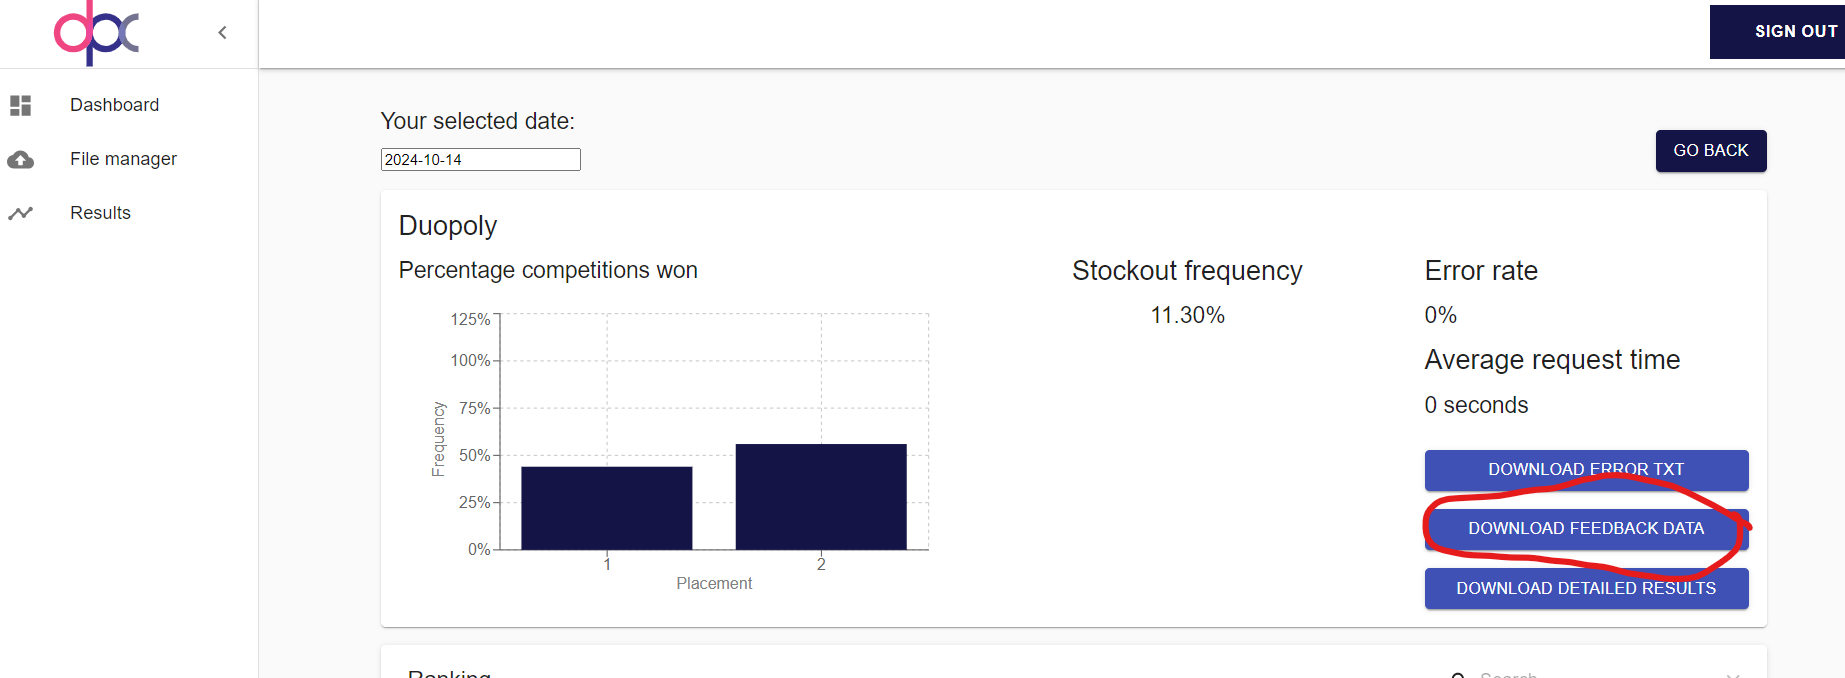

In [8]:
with open('duopoly_feedback.data', 'rb') as handle:
    feedback = pickle.load(handle)

C:\Users\creep\AppData\Local\Temp\ipykernel_14664\3661343792.py:2: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  feedback = pickle.load(handle)


In [9]:
feedback.keys()

dict_keys(['history', 'current_simulation', 'cumulative_revenue_current_selling_season'])

In [10]:
feedback['history'].head(10)

,simulation,day,season,demand,own_price,competitor_price,remaining_capacity,revenue,cumulative_revenue
0,ef945f67-f564-418e-931c-0789bd589d63,1.0,1.0,0.0,41.837023,27.396698,80.0,0.000000,0.000000
1,ef945f67-f564-418e-931c-0789bd589d63,2.0,1.0,0.0,41.837023,41.837023,80.0,0.000000,0.000000
2,ef945f67-f564-418e-931c-0789bd589d63,3.0,1.0,0.0,41.837023,41.837023,80.0,0.000000,0.000000
3,ef945f67-f564-418e-931c-0789bd589d63,4.0,1.0,1.0,41.837023,41.837023,79.0,41.837023,41.837023
4,ef945f67-f564-418e-931c-0789bd589d63,5.0,1.0,0.0,41.837023,41.837023,79.0,0.000000,41.837023
5,ef945f67-f564-418e-931c-0789bd589d63,6.0,1.0,0.0,27.891349,41.837023,79.0,0.000000,41.837023
6,ef945f67-f564-418e-931c-0789bd589d63,7.0,1.0,0.0,27.891349,27.891349,79.0,0.000000,41.837023
7,ef945f67-f564-418e-931c-0789bd589d63,8.0,1.0,1.0,27.891349,27.891349,78.0,27.891349,69.728372
8,ef945f67-f564-418e-931c-0789bd589d63,9.0,1.0,0.0,27.891349,27.891349,78.0,0.000000,69.728372
9,ef945f67-f564-418e-931c-0789bd589d63,10.0,1.0,0.0,27.891349,27.891349,78.0,0.000000,69.728372


In [11]:
feedback['current_simulation']

'f0a08126-b469-493c-b9f0-9975c880851a'

In [12]:
feedback['cumulative_revenue_current_selling_season']

np.float64(786.3961490153454)

## (2) load duopoly_competition_details.csv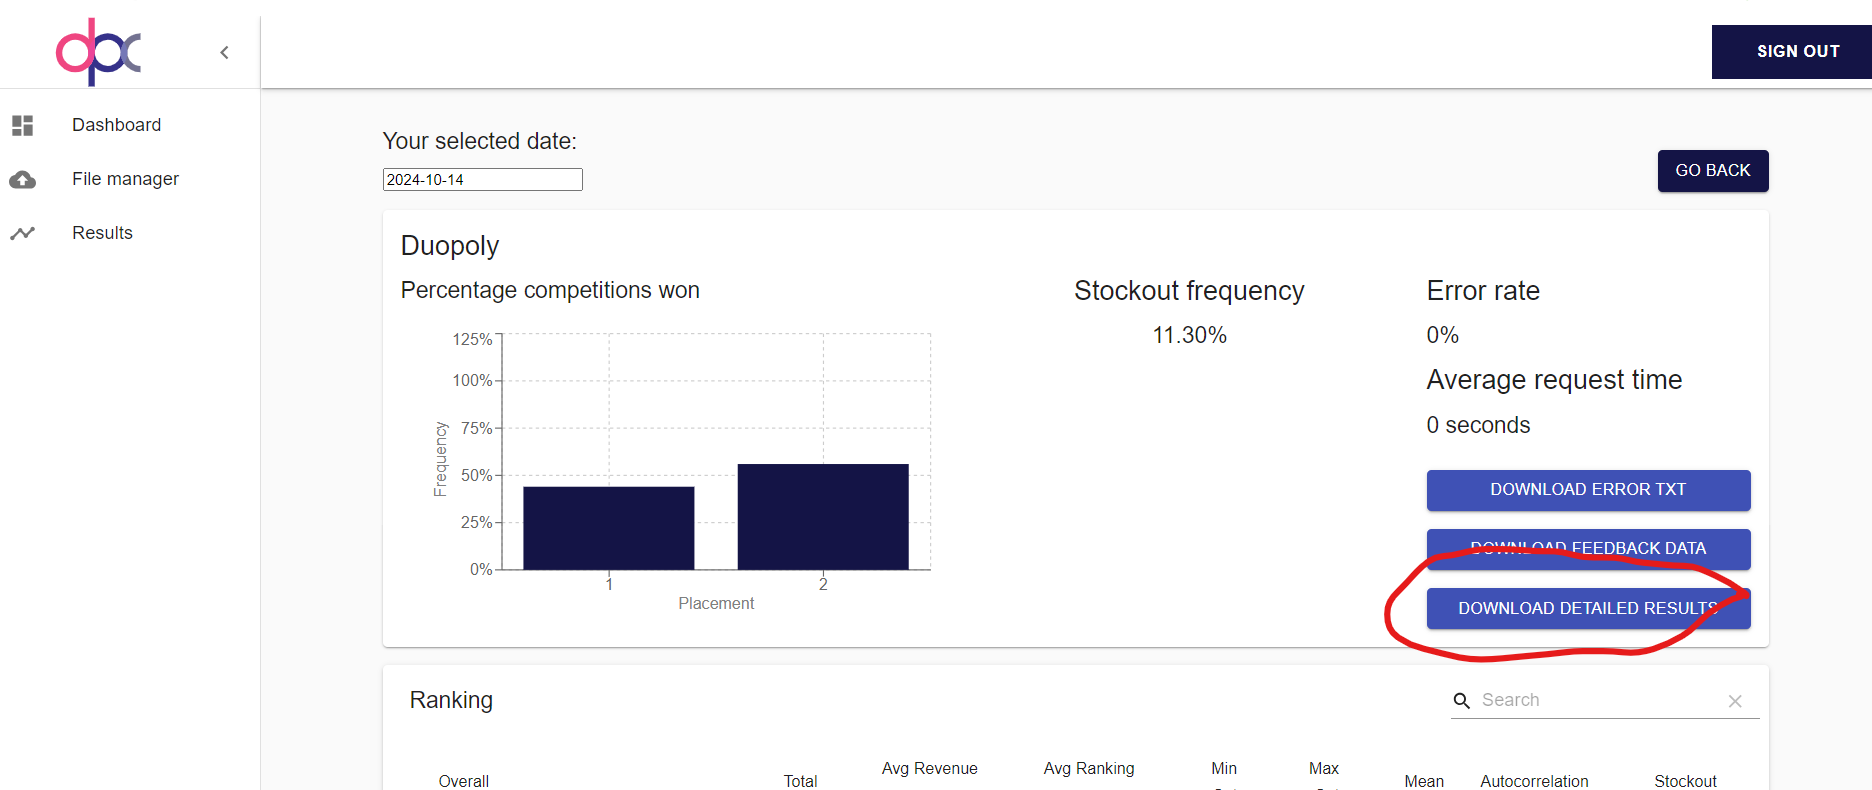

In [26]:
df_comp_details = pd.read_csv('duopoly_competition_details_bad.csv')
df_comp_details.head(10)

,competition_id,selling_season,selling_period,competitor_id,price_competitor,price,demand,competitor_has_capacity,calculation_duration,errors
0,339UBs,1,1,HospitableBeaver,50.0,65.0,0,True,0.0,NaN
1,339UBs,1,2,HospitableBeaver,1.0,65.0,0,True,0.0,NaN
2,339UBs,1,3,HospitableBeaver,1.0,65.0,0,True,0.0,NaN
3,339UBs,1,4,HospitableBeaver,1.0,32.5,0,True,0.0,NaN
4,339UBs,1,5,HospitableBeaver,1.0,32.5,0,True,0.0,NaN
5,339UBs,1,6,HospitableBeaver,1.0,32.5,0,True,0.0,NaN
6,339UBs,1,7,HospitableBeaver,1.0,30.0,0,True,0.0,NaN
7,339UBs,1,8,HospitableBeaver,1.0,30.0,0,True,0.0,NaN
8,339UBs,1,9,HospitableBeaver,1.0,30.0,0,True,0.0,NaN
9,339UBs,1,10,HospitableBeaver,1.0,30.0,0,True,0.0,NaN


In [27]:
df_comp_details.groupby('competitor_id').agg({
    'competition_id' : 'nunique',
    'selling_season' : ['max', 'count']
})

competition_id selling_season       
                         nunique            max  count
competitor_id                                         
ElectricButterfly              1            100  10000
HospitableBeaver               1            100  10000
UnbiasedCurassow               2            100  20000

### create unique selling_season_id

In [28]:
df_comp_details['unique_selling_season_key'] = df_comp_details.apply(lambda r:
                                "%s_%s" % (r.competition_id,r.selling_season), axis=1)

df_comp_details.head(3)

,competition_id,selling_season,selling_period,competitor_id,price_competitor,price,demand,competitor_has_capacity,calculation_duration,errors,unique_selling_season_key
0,339UBs,1,1,HospitableBeaver,50.0,65.0,0,True,0.0,NaN,339UBs_1
1,339UBs,1,2,HospitableBeaver,1.0,65.0,0,True,0.0,NaN,339UBs_1
2,339UBs,1,3,HospitableBeaver,1.0,65.0,0,True,0.0,NaN,339UBs_1


#### show revenue distribution over all selling seasons

In [29]:
df_comp_details['revenue'] = df_comp_details['demand'] * df_comp_details['price']

In [30]:
dfx_rev = df_comp_details.groupby('unique_selling_season_key').agg({
    'revenue' : 'sum'
}).reset_index()

dfx_rev.head()

,unique_selling_season_key,revenue
0,339UBs_1,0.0
1,339UBs_10,30.0
2,339UBs_100,90.0
3,339UBs_11,30.0
4,339UBs_12,60.0


array([[<Axes: title={'center': 'revenue'}>]], dtype=object)

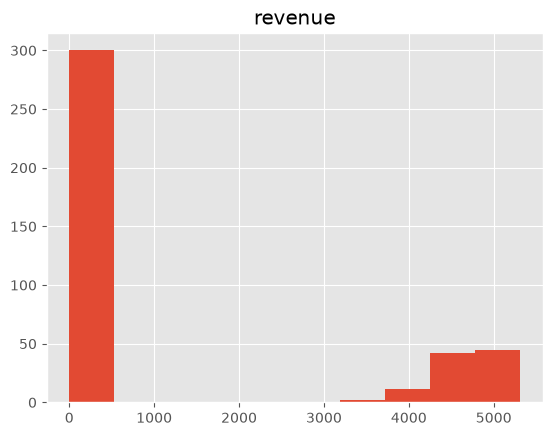

In [31]:
dfx_rev.hist()

In [32]:
dfx_rev_top = dfx_rev.sort_values('revenue', ascending=False)

dfx_rev_top.head(10)

,unique_selling_season_key,revenue
215,4EWNCR_22,5311.6
202,4EWNCR_100,5225.5
244,4EWNCR_49,5193.5
273,4EWNCR_75,5193.3
277,4EWNCR_79,5165.4
280,4EWNCR_81,5123.0
274,4EWNCR_76,5111.8
204,4EWNCR_12,5093.9
275,4EWNCR_77,5077.0
291,4EWNCR_91,5070.0


### visualize the results of one selling season

In [33]:
id = dfx_rev_top['unique_selling_season_key'].values[1]

df_aux = df_comp_details[df_comp_details.unique_selling_season_key==id]
df_aux.head(10)

,competition_id,selling_season,selling_period,competitor_id,price_competitor,price,demand,competitor_has_capacity,calculation_duration,errors,unique_selling_season_key,revenue
29900,4EWNCR,100,1,UnbiasedCurassow,100.0,65.0,3,True,0.0,NaN,4EWNCR_100,195.0
29901,4EWNCR,100,2,UnbiasedCurassow,100.0,65.0,4,True,0.0,NaN,4EWNCR_100,260.0
29902,4EWNCR,100,3,UnbiasedCurassow,100.0,65.0,3,True,0.0,NaN,4EWNCR_100,195.0
29903,4EWNCR,100,4,UnbiasedCurassow,69.5,150.0,0,True,0.0,NaN,4EWNCR_100,0.0
29904,4EWNCR,100,5,UnbiasedCurassow,100.0,150.0,0,True,0.0,NaN,4EWNCR_100,0.0
29905,4EWNCR,100,6,UnbiasedCurassow,71.0,150.0,0,True,0.0,NaN,4EWNCR_100,0.0
29906,4EWNCR,100,7,UnbiasedCurassow,100.0,150.0,0,True,0.0,NaN,4EWNCR_100,0.0
29907,4EWNCR,100,8,UnbiasedCurassow,87.5,150.0,0,True,0.0,NaN,4EWNCR_100,0.0
29908,4EWNCR,100,9,UnbiasedCurassow,74.5,150.0,0,True,0.0,NaN,4EWNCR_100,0.0
29909,4EWNCR,100,10,UnbiasedCurassow,88.0,150.0,0,True,0.0,NaN,4EWNCR_100,0.0


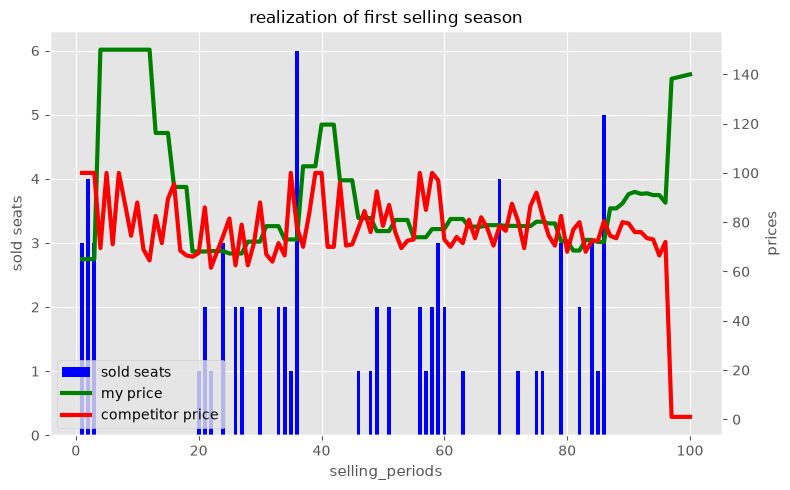

In [34]:
fig, ax = plt.subplots(figsize=(8,5))

ax.bar(df_aux.selling_period, df_aux.demand, color='b', width=0.6, align='center', label = 'sold seats')
ax.set_xlabel('selling_periods', size=11)
# ax.set_xticks(np.arange(min(dft.index), max(dft.index)+1, 1.0))
ax.set_ylabel("sold seats" , size=11)

ax_2 = ax.twinx()
ax_2.grid(False)
ax_2.plot(df_aux.selling_period, df_aux.price, color='g', linestyle='-', linewidth=3, label = 'my price')
ax_2.plot(df_aux.selling_period, df_aux.price_competitor, color='r', linestyle='-', linewidth=3, label = 'competitor price')
ax_2.tick_params(axis="both", labelsize=10)
ax_2.set_ylabel("prices" , size=11)

ax.tick_params(axis="both", labelsize=10)
ax.set_title("realization of first selling season", size=12)

# legend
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax_2.get_legend_handles_labels()
ax_2.legend(lines + lines2, labels + labels2, loc=0)

ax.grid(True)
fig.tight_layout()

plt.show()

# Plot the Capacity Utilization Curve

**capacity utilization = sold quantity / capacity**

In [35]:
df_aux['cum_demand'] = df_aux['demand'].cumsum()
df_aux['cap_util'] = round(df_aux[ 'cum_demand'] / 80 ,2)
df_aux.tail(5)

,competition_id,selling_season,selling_period,competitor_id,price_competitor,price,demand,competitor_has_capacity,calculation_duration,errors,unique_selling_season_key,revenue,cum_demand,cap_util
29995,4EWNCR,100,96,UnbiasedCurassow,72.0,87.9,0,True,0.0,NaN,4EWNCR_100,0.0,72,0.9
29996,4EWNCR,100,97,UnbiasedCurassow,1.0,138.2,0,False,0.0,NaN,4EWNCR_100,0.0,72,0.9
29997,4EWNCR,100,98,UnbiasedCurassow,1.0,138.8,0,False,0.0,NaN,4EWNCR_100,0.0,72,0.9
29998,4EWNCR,100,99,UnbiasedCurassow,1.0,139.4,0,False,0.0,NaN,4EWNCR_100,0.0,72,0.9
29999,4EWNCR,100,100,UnbiasedCurassow,1.0,140.0,0,False,0.0,NaN,4EWNCR_100,0.0,72,0.9


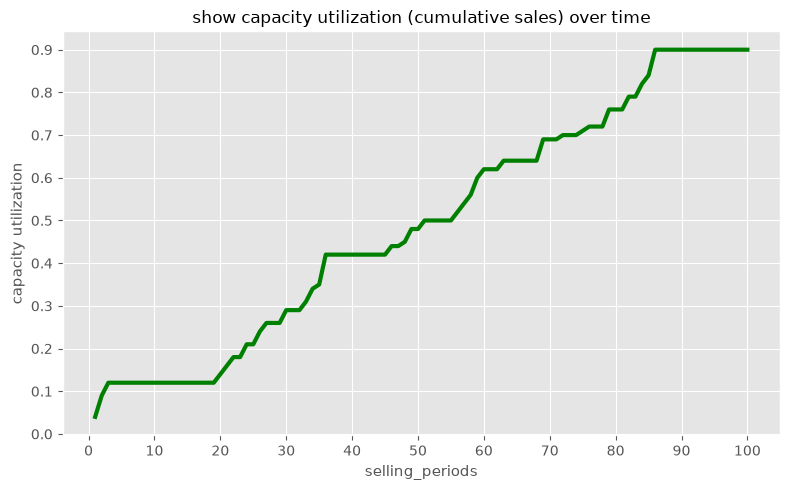

In [36]:
fig, ax = plt.subplots(figsize=(8,5))

# ax.plot(df_aux.selling_period, df_aux.cum_demand, color='b', 
#        width=0.6, align='center', label = 'sold seats')
ax.plot(df_aux.selling_period, df_aux.cap_util, color='g', 
        linestyle='-', linewidth=3, label = 'capacity utilization')
ax.set_xlabel('selling_periods', size=11)
# ax.set_xticks(np.arange(min(dft.index), max(dft.index)+1, 1.0))
ax.set_ylabel("capacity utilization" , size=11)

y_majorLocator = MultipleLocator(0.1)
ax.yaxis.set_major_locator(y_majorLocator)
x_majorLocator = MultipleLocator(10)
ax.xaxis.set_major_locator(x_majorLocator)

ax.set_title("show capacity utilization (cumulative sales) over time", size=12)
# ax.legend(loc=0)

ax.grid(True)
fig.tight_layout()

plt.show()